In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('form_responses.csv')
df.sort_values(by='Timestamp', inplace=True)

In [3]:
df.drop(columns=['Timestamp'], inplace=True)

In [4]:
df.head()

df.sex = df['sex'].replace({'Femmina': 0, 'Maschio': 1})

C:\Users\Gabri\AppData\Local\Temp\ipykernel_23568\2001170994.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.sex = df['sex'].replace({'Femmina': 0, 'Maschio': 1})


In [6]:
df.train_years = df['train_years'].replace({'Meno di 1': 0.5 , 'Più di 10': 11})

In [8]:
df.z2_train_week = df.z2_train_week.fillna(0)
df.fartelk_train_week = df.fartelk_train_week.fillna(0)
df.power_train_week = df.power_train_week.fillna(0)

In [9]:
df.avg_km_week = df['avg_km_week'].replace({'Più di 80': 85})

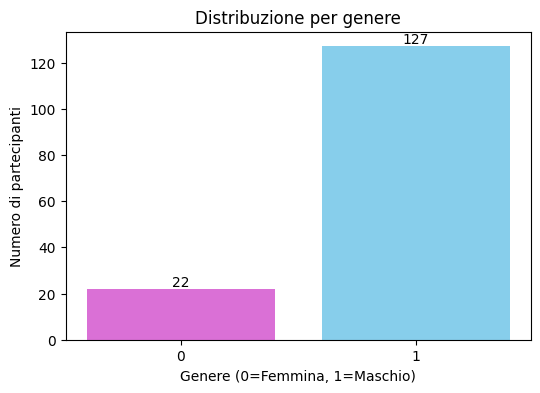

In [16]:
gender_counts = df['sex'].value_counts().sort_index()
plt.figure(figsize=(6, 4))
bars = plt.bar(gender_counts.index.astype(str), gender_counts.values, color=['orchid', 'skyblue'])
plt.xlabel('Genere (0=Femmina, 1=Maschio)')
plt.ylabel('Numero di partecipanti')
plt.title('Distribuzione per genere')

# Aggiungi il numero sopra ogni barra
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom')

plt.show()


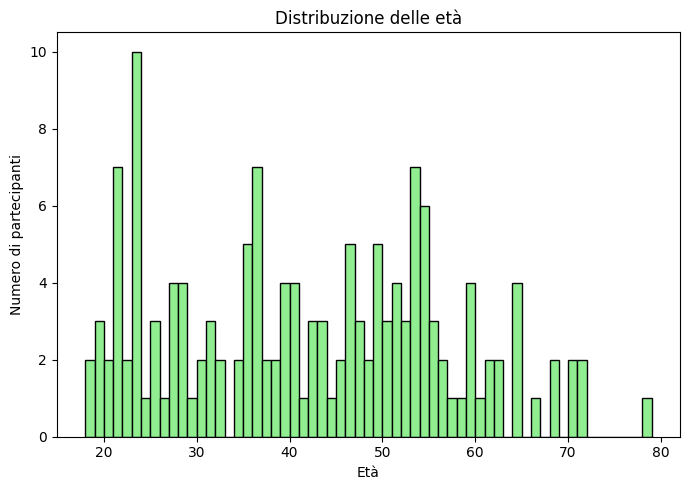

In [19]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.hist(df['age'], bins=range(df['age'].min(), df['age'].max() + 2), color='lightgreen', edgecolor='black')
ax.set_xlabel('Età')
ax.set_ylabel('Numero di partecipanti')
ax.set_title('Distribuzione delle età')

plt.tight_layout()
plt.show()



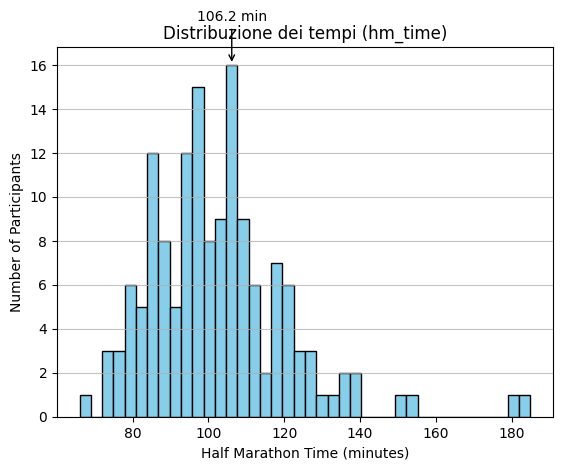

In [ ]:
# Convert 'hm_time' to seconds for plotting
hm_time_sec = pd.to_timedelta(df['hm_time']).dt.total_seconds() / 60  # minutes

plt.figure(figsize=(10, 6))
plt.hist(hm_time_sec, bins=40, color='skyblue', edgecolor='black')
plt.xlabel('Half Marathon Time (minutes)')
plt.ylabel('Number of Participants')
plt.title('Distribuzione dei tempi (hm_time)')
plt.grid(axis='y', alpha=0.75)
plt.show()

In [27]:
hm_time_sec = pd.to_timedelta(df['hm_time']).dt.total_seconds() / 60  # minutes

hm_time_sec.mean(), hm_time_sec.std()

(np.float64(102.52774049217003), np.float64(18.64487583587522))

Deviazione standard molto alta, fa intuire che sono state ricevute risposte da runner esperti e da amatori

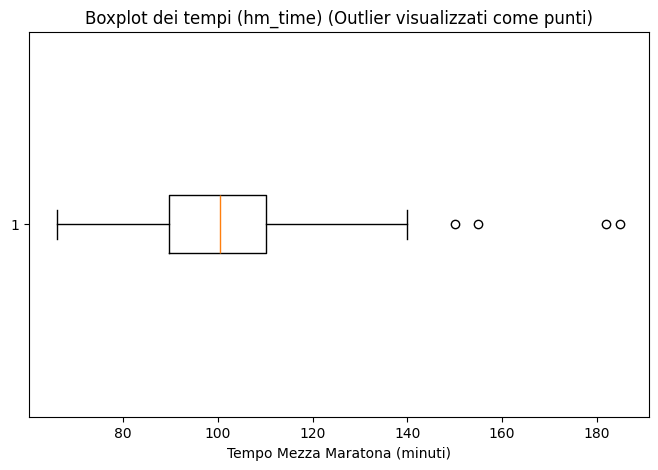

In [29]:
plt.figure(figsize=(8, 5))
plt.boxplot(hm_time_sec, vert=False)
plt.xlabel('Tempo Mezza Maratona (minuti)')
plt.title('Boxplot dei tempi (hm_time) (Outlier visualizzati come punti)')
plt.show()

Infatti qui possiamo notare gli outlier che alzano la deviazione standard